# Simulating galaxy images with GalSim

First step of the `StatCal` plan in `readme.md`: generate fake galaxy postage stamps with a known
**intrinsic ellipticity**, a known **cosmic shear**, and a **PSF that depends on detector position**.
The PSF is an optical PSF whose Zernike aberrations take different values in each of the four
cells (quadrants) of the detector frame.

Forward model for galaxy $i$ at detector position $(x_i, y_i)$:

$$
I_i = \mathrm{Pixel} \ast \mathrm{PSF}\big(\mathbf{a}_{c(x_i,y_i)}\big) \ast \big[\, G_\gamma\, G_{e_i}\, \mathrm{Sersic}(n, r_{1/2}) \big] + \text{noise}
$$

where $G_e$ and $G_\gamma$ are shear operations, and $\mathbf{a}_c$ are the Zernike amplitudes of cell $c$.
Stamp size and pixel scale match `background.py`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import galsim

# Stamp/pixel settings shared with background.py
NX = NY = 64
PIXELSCALE = 0.1   # arcsec / pixel
GAL_HLR = 0.4      # arcsec

rng = np.random.default_rng(42)
galsim_rng = galsim.BaseDeviate(42)

## Detector-dependent PSF

Each quadrant of the detector has its own set of Zernike amplitudes (in waves, Noll indexing:
4 = defocus, 5–6 = astigmatism, 7–8 = coma, 11 = spherical). `lam_over_diam` ≈ 700 nm / 1.2 m ≈ 0.12″,
roughly Euclid VIS. These are the "true" PSF parameters that we will later try to infer.

In [2]:
LAM_OVER_DIAM = 0.12  # arcsec
OBSCURATION = 0.3

# Noll index -> name, for plotting
ZERNIKE_NAMES = {4: "defocus", 5: "astig 1", 6: "astig 2", 7: "coma 1", 8: "coma 2", 11: "spherical"}

# True Zernike amplitudes per detector cell (waves). Cells: 0=bottom-left, 1=bottom-right, 2=top-left, 3=top-right
TRUE_ZERNIKES = {
    0: {4: 0.05, 5: 0.06, 6: 0.00, 7: 0.00, 8: 0.02, 11: 0.01},
    1: {4: -0.03, 5: -0.04, 6: 0.05, 7: 0.03, 8: 0.00, 11: 0.01},
    2: {4: 0.08, 5: 0.00, 6: -0.06, 7: -0.02, 8: 0.03, 11: 0.00},
    3: {4: 0.00, 5: 0.08, 6: 0.04, 7: 0.00, 8: -0.04, 11: 0.02},
}

def detector_cell(x, y):
    # x, y in [0, 1): detector-frame coordinates
    return 2 * int(y >= 0.5) + int(x >= 0.5)

def make_psf(zernikes):
    aberrations = np.zeros(12)
    for j, a in zernikes.items():
        aberrations[j] = a
    return galsim.OpticalPSF(lam_over_diam=LAM_OVER_DIAM, obscuration=OBSCURATION,
                             aberrations=aberrations)

PSFS = {c: make_psf(z) for c, z in TRUE_ZERNIKES.items()}

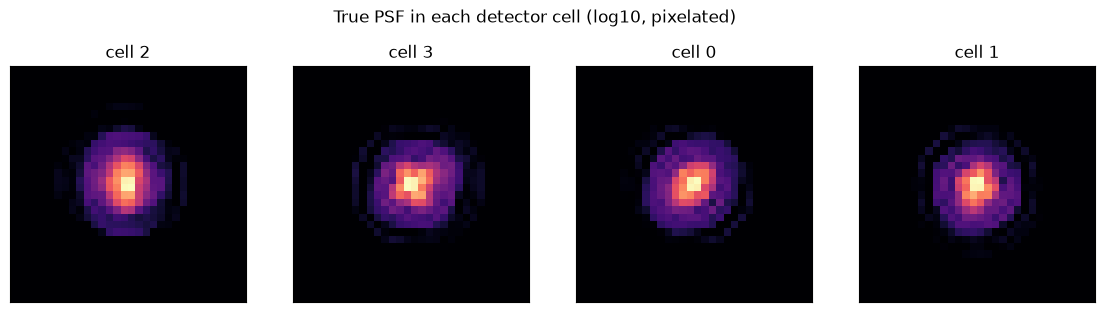

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for c, ax in zip([2, 3, 0, 1], axes):
    img = PSFS[c].drawImage(nx=32, ny=32, scale=PIXELSCALE).array
    ax.imshow(np.log10(np.clip(img, 1e-5, None)), origin="lower", cmap="magma", vmin=-4)
    ax.set_title(f"cell {c}")
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("True PSF in each detector cell (log10, pixelated)")
plt.show()

## A single galaxy, step by step

Intrinsic shape → add intrinsic ellipticity → apply cosmic shear → convolve with the PSF → pixelate and add noise.
The shear is exaggerated here so the effect is visible.

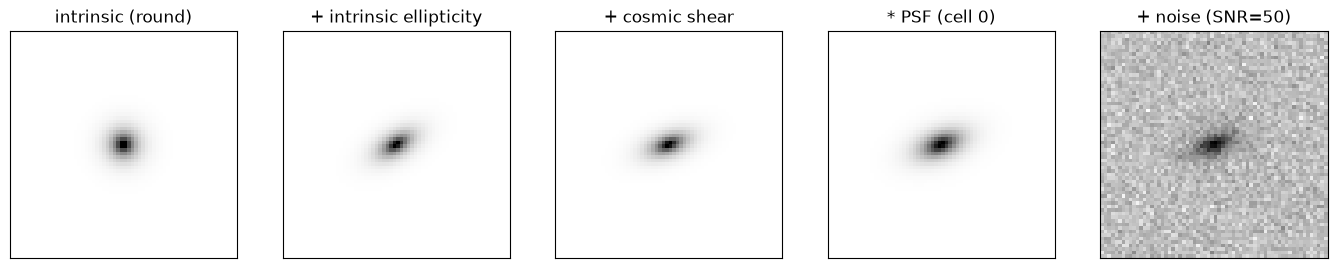

In [4]:
def draw(obj):
    return obj.drawImage(nx=NX, ny=NY, scale=PIXELSCALE).array

gal0 = galsim.Sersic(n=1, half_light_radius=GAL_HLR, flux=1000)
e_int = galsim.Shear(g=0.3, beta=30 * galsim.degrees)
g_lens = galsim.Shear(g1=0.1, g2=-0.05)

gal_int = gal0.shear(e_int)
gal_sheared = gal_int.shear(g_lens)
observed = galsim.Convolve(gal_sheared, PSFS[0])

noisy = observed.drawImage(nx=NX, ny=NY, scale=PIXELSCALE)
noisy.addNoiseSNR(galsim.GaussianNoise(galsim_rng), snr=50, preserve_flux=True)

panels = {
    "intrinsic (round)": draw(gal0),
    "+ intrinsic ellipticity": draw(gal_int),
    "+ cosmic shear": draw(gal_sheared),
    "* PSF (cell 0)": draw(observed),
    "+ noise (SNR=50)": noisy.array,
}
fig, axes = plt.subplots(1, 5, figsize=(17, 3.6))
for ax, (title, img) in zip(axes, panels.items()):
    ax.imshow(img, origin="lower", cmap="gray_r")
    ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([])
plt.show()

## A population of galaxies across the detector

Draw ~200 galaxies (the sample size suggested in the readme) with:
- uniform positions on the detector frame, which set the PSF via the cell,
- intrinsic ellipticities $e_1, e_2 \sim \mathcal{N}(0, \sigma_e^2)$,
- a constant cosmic shear $\gamma$ (could later be made spatially varying),
- a spread of half-light radii and fluxes.

We keep all true parameters so they can be compared with inferred values later.

In [5]:
N_GAL = 200
SIGMA_E = 0.25
TRUE_SHEAR = (0.02, -0.01)
NOISE_SIGMA = 1.0  # per-pixel Gaussian noise

def sample_ellipticity(sigma_e, rng):
    while True:
        e1, e2 = rng.normal(0, sigma_e, size=2)
        if np.hypot(e1, e2) < 0.9:
            return e1, e2

catalog = []
for i in range(N_GAL):
    x, y = rng.uniform(0, 1, size=2)
    e1, e2 = sample_ellipticity(SIGMA_E, rng)
    catalog.append(dict(
        x=x, y=y, cell=detector_cell(x, y),
        e1=e1, e2=e2,
        g1=TRUE_SHEAR[0], g2=TRUE_SHEAR[1],
        hlr=rng.lognormal(np.log(GAL_HLR), 0.25),
        flux=rng.lognormal(np.log(1000), 0.4),
        n=rng.choice([1.0, 1.5, 2.5, 4.0]),
    ))

def render(gal, noise_sigma=NOISE_SIGMA, seed=None):
    obj = galsim.Sersic(n=gal["n"], half_light_radius=gal["hlr"], flux=gal["flux"])
    obj = obj.shear(g1=gal["e1"], g2=gal["e2"]).shear(g1=gal["g1"], g2=gal["g2"])
    obj = galsim.Convolve(obj, PSFS[gal["cell"]])
    img = obj.drawImage(nx=NX, ny=NY, scale=PIXELSCALE)
    if noise_sigma > 0:
        img.addNoise(galsim.GaussianNoise(galsim.BaseDeviate(seed), sigma=noise_sigma))
    return img.array

images = np.array([render(gal, seed=1000 + i) for i, gal in enumerate(catalog)])
images.shape

(200, 64, 64)

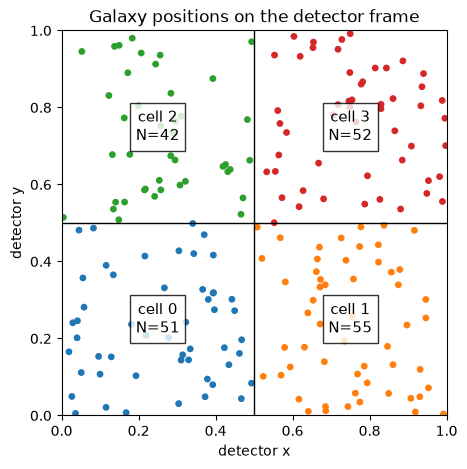

In [6]:
xs = np.array([g["x"] for g in catalog])
ys = np.array([g["y"] for g in catalog])
cells = np.array([g["cell"] for g in catalog])

fig, ax = plt.subplots(figsize=(5, 5))
sc = ax.scatter(xs, ys, c=cells, cmap="tab10", vmin=0, vmax=9, s=15)
ax.axhline(0.5, color="k", lw=1); ax.axvline(0.5, color="k", lw=1)
for c, (cx, cy) in {0: (0.25, 0.25), 1: (0.75, 0.25), 2: (0.25, 0.75), 3: (0.75, 0.75)}.items():
    ax.text(cx, cy, f"cell {c}\nN={np.sum(cells == c)}", ha="center", va="center",
            fontsize=11, bbox=dict(fc="white", alpha=0.8))
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
ax.set_xlabel("detector x"); ax.set_ylabel("detector y")
ax.set_title("Galaxy positions on the detector frame")
plt.show()

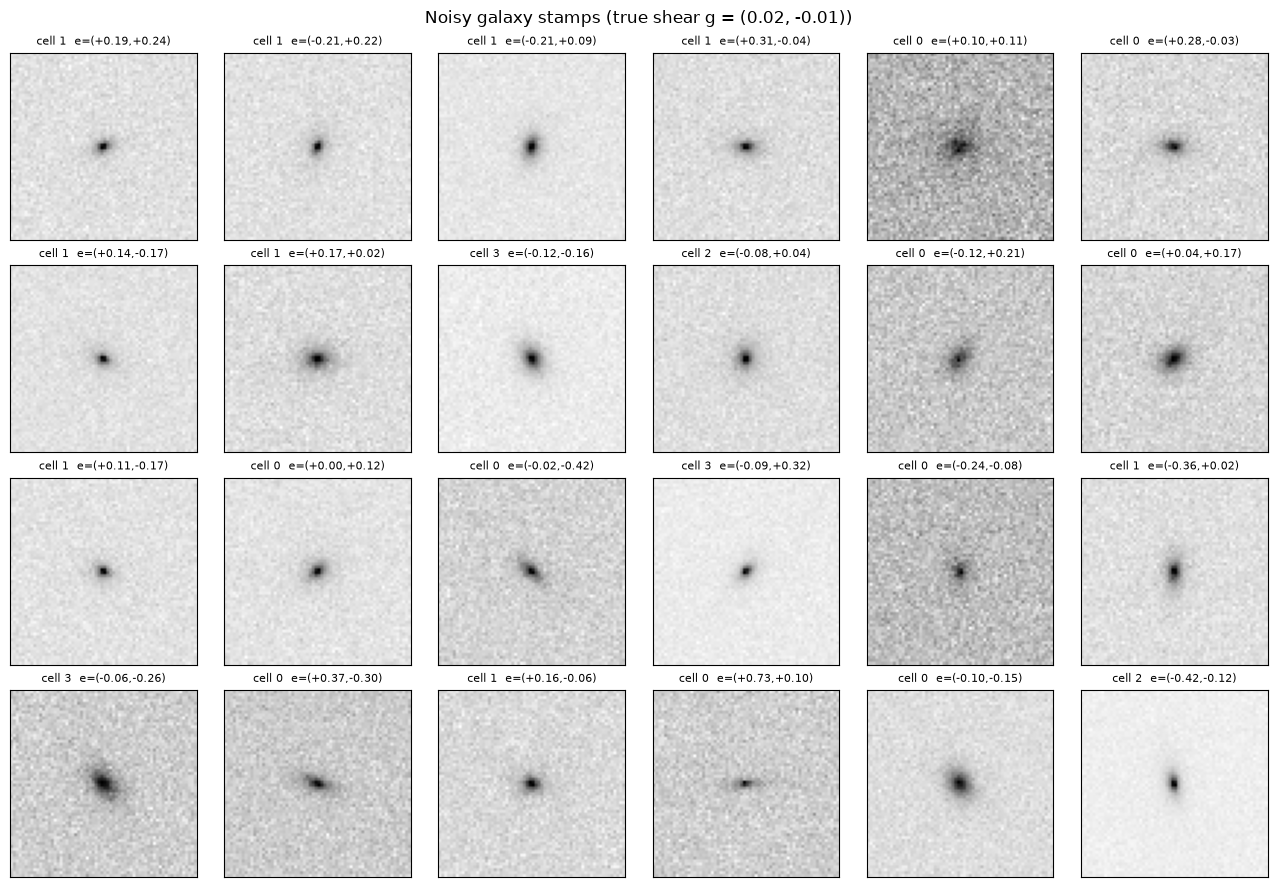

In [7]:
n_show = 24
fig, axes = plt.subplots(4, 6, figsize=(13, 9))
for ax, i in zip(axes.flat, range(n_show)):
    g = catalog[i]
    ax.imshow(images[i], origin="lower", cmap="gray_r")
    ax.set_title(f"cell {g['cell']}  e=({g['e1']:+.2f},{g['e2']:+.2f})", fontsize=8)
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f"Noisy galaxy stamps (true shear g = {TRUE_SHEAR})")
plt.tight_layout()
plt.show()

## Same galaxy, different detector cells

To see the PSF imprint directly, render one galaxy (noise-free, no shear) through each cell's PSF
and show the residual against the cell-average.

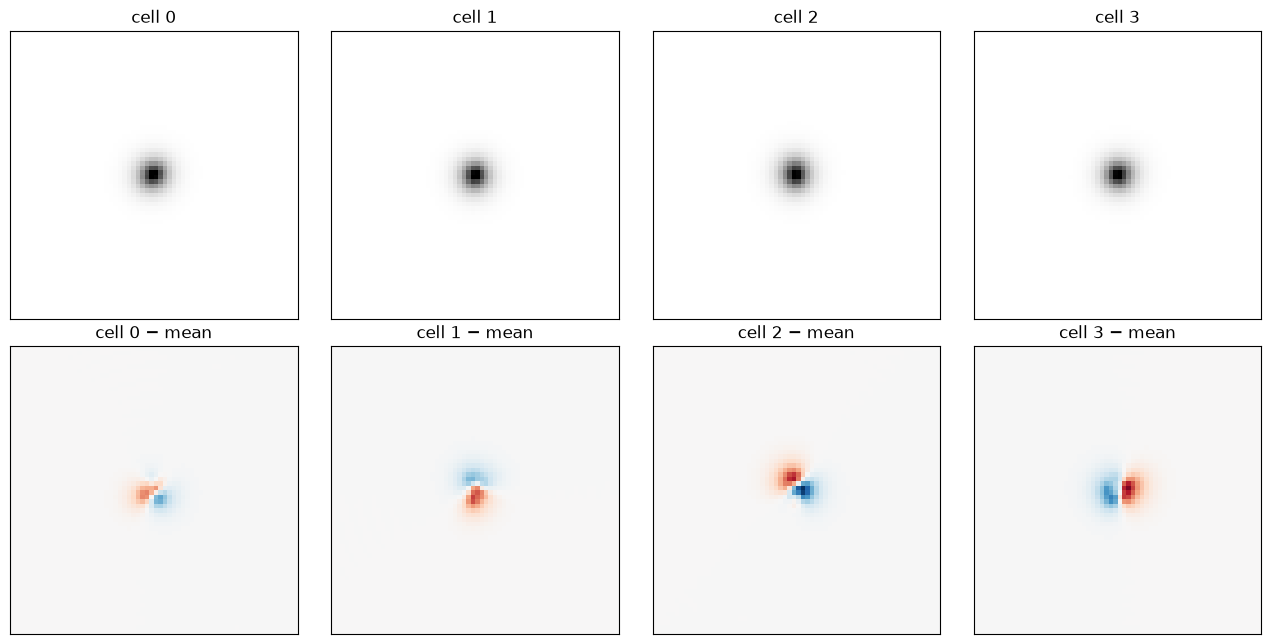

In [8]:
ref = dict(catalog[0], e1=0.0, e2=0.0, g1=0.0, g2=0.0, n=1.0, hlr=0.25, flux=1000)
by_cell = {c: render(dict(ref, cell=c), noise_sigma=0) for c in range(4)}
mean_img = np.mean(list(by_cell.values()), axis=0)

fig, axes = plt.subplots(2, 4, figsize=(13, 6.5))
vmax = np.abs(np.array(list(by_cell.values())) - mean_img).max()
for c in range(4):
    axes[0, c].imshow(by_cell[c], origin="lower", cmap="gray_r")
    axes[0, c].set_title(f"cell {c}")
    axes[1, c].imshow(by_cell[c] - mean_img, origin="lower", cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    axes[1, c].set_title(f"cell {c} − mean")
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

## Next steps

- Feed `images` into the moments / MetaCal code in `background.py` to measure shears (MetaCal needs
  the PSF to deconvolve and reconvolve, so it will use each cell's PSF model).
- Replace the fixed `TRUE_ZERNIKES` with parameters inferred jointly with the shears (HMC), using the
  ~200 noisy stamps and their detector positions.